# VV_XXXX analysis in R3

This notebook explores the round 3 voucher family, i.e. the VEV strike ladder on Velvetfruit Extract. Day 2 is held out and excluded here so it stays available for backtest validation later.

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams['figure.figsize'] = (16, 6)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

def find_data_dir() -> Path:
    for candidate in (Path('R3/Data'), Path('../Data'), Path('Data')):
        if candidate.exists():
            return candidate
    raise FileNotFoundError('Could not find R3/Data from the current notebook location.')

DATA_DIR = find_data_dir()
HOLDOUT_DAY = 2

price_files = [path for path in sorted(DATA_DIR.glob('prices_round_3_day_*.csv')) if int(path.stem.split('_day_')[-1]) != HOLDOUT_DAY]
trade_files = [path for path in sorted(DATA_DIR.glob('trades_round_3_day_*.csv')) if int(path.stem.split('_day_')[-1]) != HOLDOUT_DAY]

prices = pd.concat([pd.read_csv(path, sep=';') for path in price_files], ignore_index=True)
trades = pd.concat([pd.read_csv(path, sep=';').assign(day=int(path.stem.split('_day_')[-1])) for path in trade_files], ignore_index=True)

voucher_products = sorted([product for product in prices['product'].unique().tolist() if product.startswith('VEV_')])
voucher_prices = prices.loc[prices['product'].isin(voucher_products)].copy()
voucher_trades = trades.loc[trades['symbol'].isin(voucher_products)].copy()

print('Data dir:', DATA_DIR)
print('Voucher products:', voucher_products)
print('Price rows:', len(prices), 'Trade rows:', len(trades))
print('Voucher price rows:', len(voucher_prices))
print('Voucher trade rows:', len(voucher_trades))
display(voucher_prices.head())
display(voucher_trades.head())

Data dir: ../Data
Voucher products: ['VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']
Price rows: 240000 Trade rows: 2715
Voucher price rows: 200000
Voucher trade rows: 1121


,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss
0,0,0,VEV_5400,22,25,NaN,NaN,NaN,NaN,24,25,NaN,NaN,NaN,NaN,23.0,0.0
1,0,0,VEV_6500,0,16,NaN,NaN,NaN,NaN,1,16,NaN,NaN,NaN,NaN,0.5,0.0
2,0,0,VEV_5500,8,25,NaN,NaN,NaN,NaN,9,25,NaN,NaN,NaN,NaN,8.5,0.0
3,0,0,VEV_5200,100,19,NaN,NaN,NaN,NaN,103,6,104.0,13.0,NaN,NaN,101.5,0.0
4,0,0,VEV_5300,52,6,51.0,19.0,NaN,NaN,54,25,NaN,NaN,NaN,NaN,53.0,0.0


,timestamp,buyer,seller,symbol,currency,price,quantity,day
1,2900,NaN,NaN,VEV_5400,XIRECS,22.0,3,0
2,2900,NaN,NaN,VEV_5500,XIRECS,8.0,3,0
3,2900,NaN,NaN,VEV_6000,XIRECS,0.0,3,0
4,2900,NaN,NaN,VEV_6500,XIRECS,0.0,3,0
8,9000,NaN,NaN,VEV_4000,XIRECS,1222.0,2,0


In [7]:
def strike_from_symbol(symbol: str) -> int:
    return int(symbol.split('_')[1])

summary_rows = []
for product in voucher_products:
    product_prices = voucher_prices.loc[voucher_prices['product'] == product].copy().sort_values(['day', 'timestamp'])
    product_trades = voucher_trades.loc[voucher_trades['symbol'] == product].copy().sort_values(['day', 'timestamp'])
    book = product_prices.assign(
        spread=product_prices['ask_price_1'] - product_prices['bid_price_1'],
        imbalance=(product_prices['bid_volume_1'] - product_prices['ask_volume_1']) / (product_prices['bid_volume_1'] + product_prices['ask_volume_1']),
        microprice=(product_prices['ask_price_1'] * product_prices['bid_volume_1'] + product_prices['bid_price_1'] * product_prices['ask_volume_1']) / (product_prices['bid_volume_1'] + product_prices['ask_volume_1']),
    )
    book['next_mid_change'] = book.groupby('day')['mid_price'].shift(-1) - book['mid_price']
    trade_mid = product_trades.merge(book[['day', 'timestamp', 'mid_price', 'spread', 'imbalance', 'microprice']], on=['day', 'timestamp'], how='left')
    trade_mid['edge_vs_mid'] = trade_mid['price'] - trade_mid['mid_price']
    summary_rows.append({
        'symbol': product,
        'strike': strike_from_symbol(product),
        'price_rows': len(book),
        'trade_rows': len(product_trades),
        'mean_mid': book['mid_price'].mean(),
        'std_mid': book['mid_price'].std(),
        'mean_spread': book['spread'].mean(),
        'trade_vwap': (trade_mid['price'] * trade_mid['quantity']).sum() / trade_mid['quantity'].sum() if len(trade_mid) else np.nan,
        'mean_edge_vs_mid': trade_mid['edge_vs_mid'].mean() if len(trade_mid) else np.nan,
        'imbalance_next_mid_corr': book['imbalance'].corr(book['next_mid_change']),
        'mean_abs_mid_change': book.groupby('day')['mid_price'].diff().abs().mean(),
    })

summary = pd.DataFrame(summary_rows).sort_values('strike')
print('Voucher strike summary:')
display(summary)

Voucher strike summary:


/Users/ericlu/Works/imcp4/imcprosp4/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/ericlu/Works/imcp4/imcprosp4/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/Users/ericlu/Works/imcp4/imcprosp4/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/ericlu/Works/imcp4/imcprosp4/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,symbol,strike,price_rows,trade_rows,mean_mid,std_mid,mean_spread,trade_vwap,mean_edge_vs_mid,imbalance_next_mid_corr,mean_abs_mid_change
0,VEV_4000,4000,20000,336,1247.466025,14.204703,20.76995,1247.858187,-0.401786,0.483653,0.921267
1,VEV_4500,4500,20000,1,747.463425,14.195962,15.79855,733.000000,3.500000,0.401720,0.868262
2,VEV_5000,5000,20000,1,253.261250,13.046775,6.00500,238.000000,1.000000,0.222234,0.731448
3,VEV_5100,5100,20000,1,166.545450,11.562136,4.28840,152.000000,1.000000,0.228063,0.628663
4,VEV_5200,5200,20000,10,96.299675,8.499258,2.90195,87.567568,-0.850000,0.301899,0.475298
5,VEV_5300,5300,20000,76,47.900850,5.418267,2.13470,45.151163,-0.980263,0.368897,0.302530
6,VEV_5400,5400,20000,145,17.060725,3.070972,1.40805,15.990079,-0.631034,0.279123,0.144914
7,VEV_5500,5500,20000,173,7.314900,1.483652,1.16670,6.586379,-0.549133,0.294642,0.065907
8,VEV_6000,6000,20000,189,0.500000,0.000000,1.00000,0.000000,-0.500000,NaN,0.000000
9,VEV_6500,6500,20000,189,0.500000,0.000000,1.00000,0.000000,-0.500000,NaN,0.000000


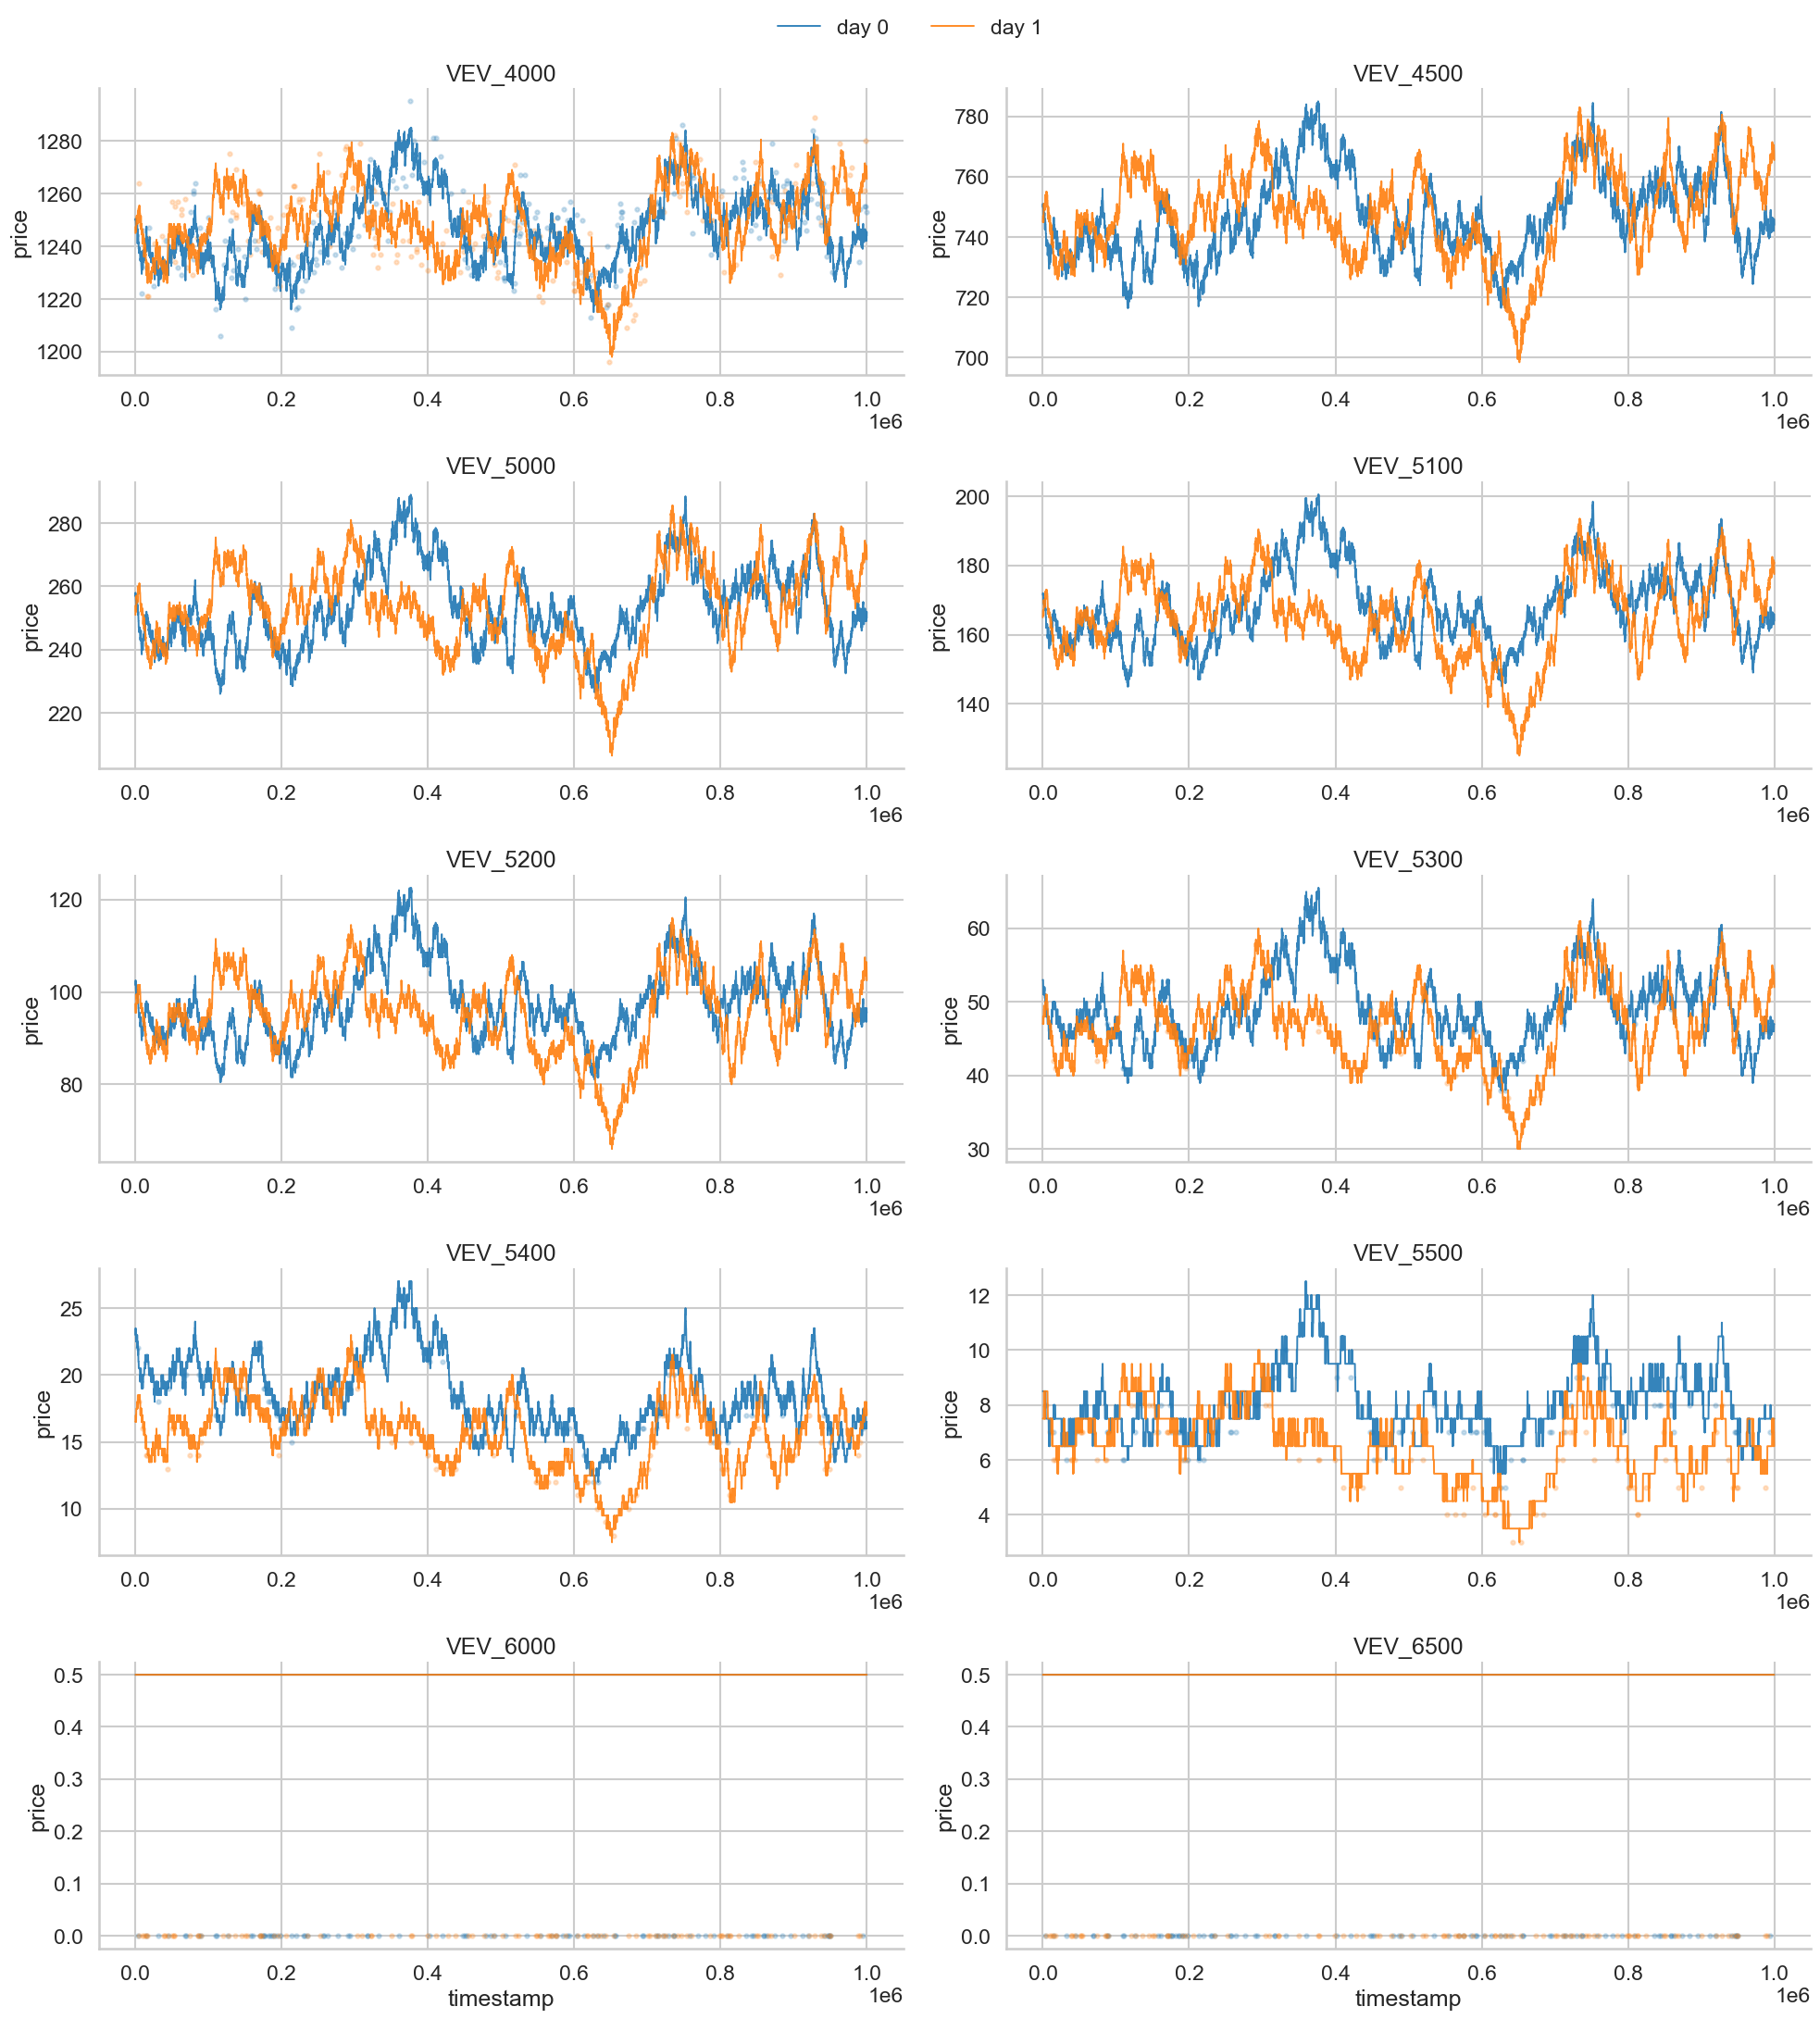

In [3]:
fig, axes = plt.subplots(5, 2, figsize=(20, 22), sharex=False)
axes = axes.flatten()

for ax, product in zip(axes, voucher_products):
    product_prices = voucher_prices.loc[voucher_prices['product'] == product].copy().sort_values(['day', 'timestamp'])
    product_trades = voucher_trades.loc[voucher_trades['symbol'] == product].copy().sort_values(['day', 'timestamp'])
    for day, color in [(0, '#1f77b4'), (1, '#ff7f0e')]:
        day_prices = product_prices.loc[product_prices['day'] == day]
        day_trades = product_trades.loc[product_trades['day'] == day]
        ax.plot(day_prices['timestamp'], day_prices['mid_price'], color=color, lw=1.4, alpha=0.9, label=f'day {day}' if product == voucher_products[0] else None)
        ax.scatter(day_trades['timestamp'], day_trades['price'], s=10, color=color, alpha=0.22)
    ax.set_title(product)
    ax.set_ylabel('price')

for ax in axes[len(voucher_products):]:
    ax.axis('off')

axes[-1].set_xlabel('timestamp')
axes[-2].set_xlabel('timestamp')
handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc='upper center', ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.98))

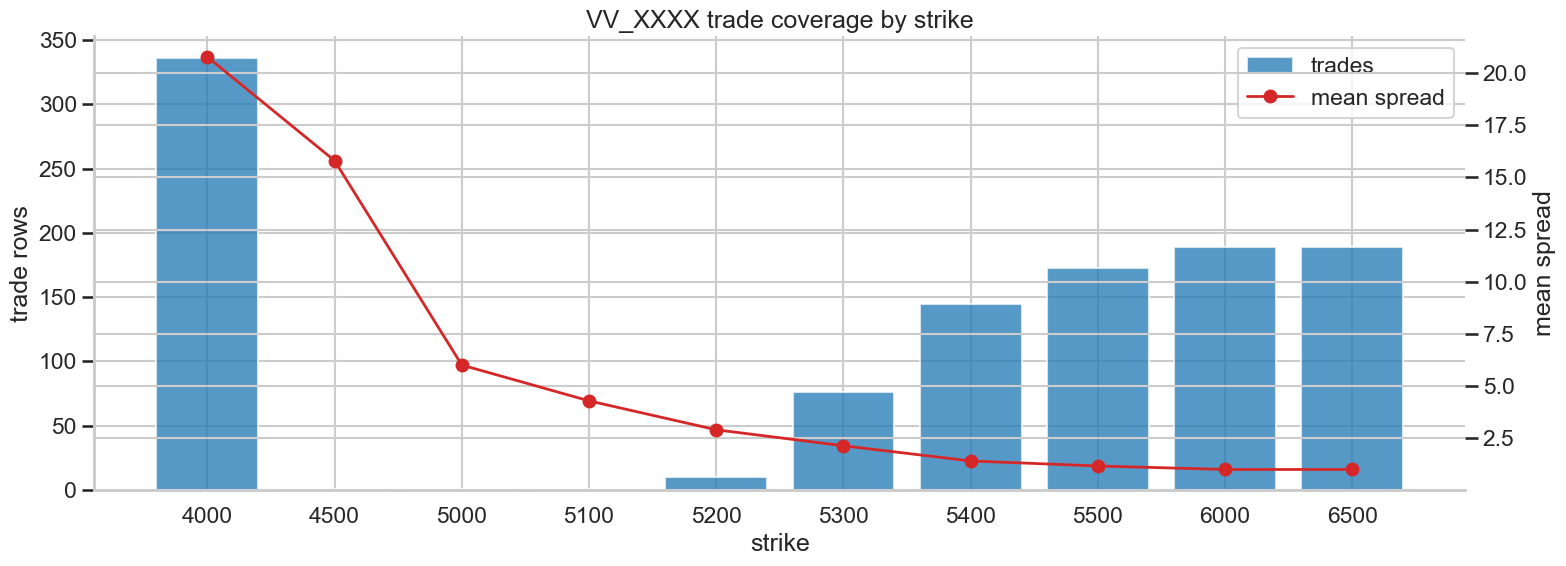

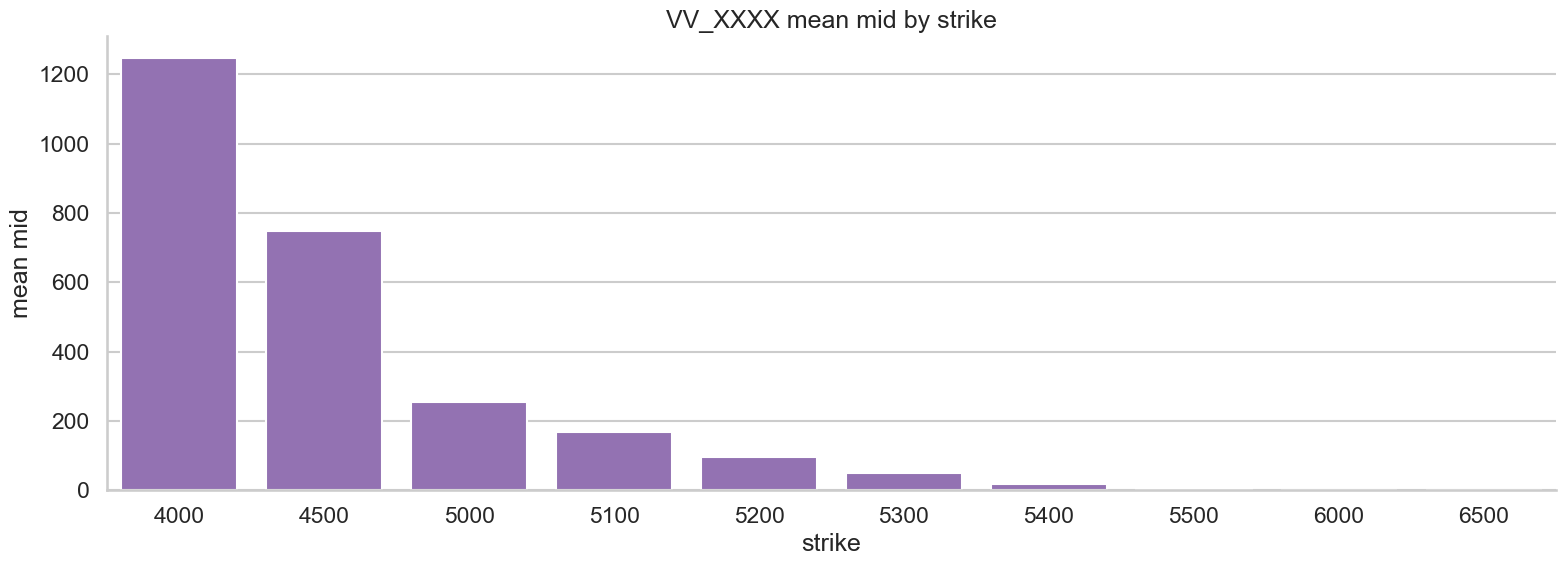

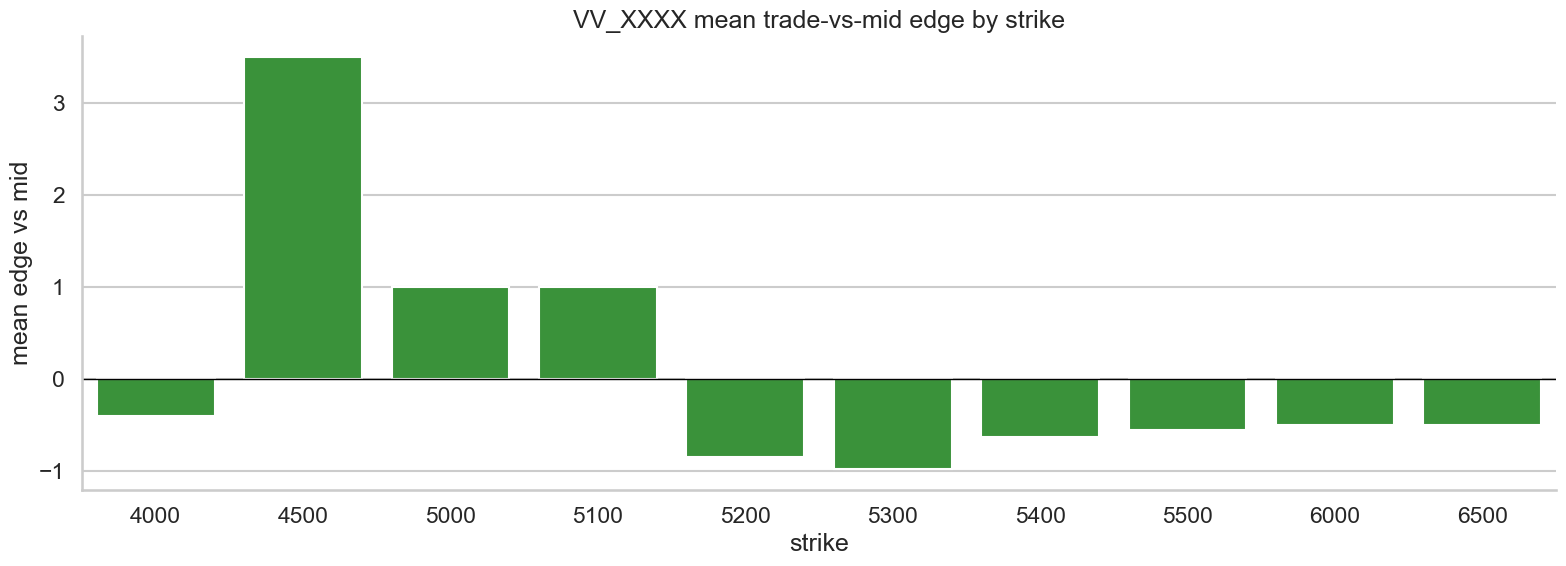

In [4]:
summary = summary.sort_values('strike').reset_index(drop=True)

fig, ax1 = plt.subplots(figsize=(16, 6))
ax1.bar(summary['strike'].astype(str), summary['trade_rows'], color='#1f77b4', alpha=0.75, label='trades')
ax1.set_ylabel('trade rows')
ax1.set_xlabel('strike')
ax1.set_title('VV_XXXX trade coverage by strike')

ax2 = ax1.twinx()
ax2.plot(summary['strike'].astype(str), summary['mean_spread'], color='#d62728', marker='o', lw=2, label='mean spread')
ax2.set_ylabel('mean spread')

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper right')
plt.xticks(rotation=45)
plt.tight_layout()

fig, ax = plt.subplots(figsize=(16, 6))
sns.barplot(data=summary, x='strike', y='mean_mid', color='#9467bd', ax=ax)
ax.set_title('VV_XXXX mean mid by strike')
ax.set_xlabel('strike')
ax.set_ylabel('mean mid')
plt.tight_layout()

fig, ax = plt.subplots(figsize=(16, 6))
sns.barplot(data=summary, x='strike', y='mean_edge_vs_mid', color='#2ca02c', ax=ax)
ax.axhline(0, color='black', lw=1)
ax.set_title('VV_XXXX mean trade-vs-mid edge by strike')
ax.set_xlabel('strike')
ax.set_ylabel('mean edge vs mid')
plt.tight_layout()

In [5]:
flat = summary.loc[summary['std_mid'].fillna(0) < 1e-9, ['symbol', 'strike', 'mean_mid', 'mean_spread', 'trade_rows']]
active = summary.loc[summary['trade_rows'] >= 50, ['symbol', 'strike', 'trade_rows', 'mean_mid', 'mean_spread', 'imbalance_next_mid_corr']]
print('Flat or pinned strikes:')
display(flat)
print('More active strikes:')
display(active)

print('Top strikes by imbalance-to-next-mid signal:')
display(summary.sort_values('imbalance_next_mid_corr', ascending=False)[['symbol', 'strike', 'imbalance_next_mid_corr', 'trade_rows', 'mean_spread']].head(10))

Flat or pinned strikes:


,symbol,strike,mean_mid,mean_spread,trade_rows
8,VEV_6000,6000,0.5,1.0,189
9,VEV_6500,6500,0.5,1.0,189


More active strikes:


,symbol,strike,trade_rows,mean_mid,mean_spread,imbalance_next_mid_corr
0,VEV_4000,4000,336,1247.466025,20.76995,0.483653
5,VEV_5300,5300,76,47.900850,2.13470,0.368897
6,VEV_5400,5400,145,17.060725,1.40805,0.279123
7,VEV_5500,5500,173,7.314900,1.16670,0.294642
8,VEV_6000,6000,189,0.500000,1.00000,NaN
9,VEV_6500,6500,189,0.500000,1.00000,NaN


Top strikes by imbalance-to-next-mid signal:


,symbol,strike,imbalance_next_mid_corr,trade_rows,mean_spread
0,VEV_4000,4000,0.483653,336,20.76995
1,VEV_4500,4500,0.401720,1,15.79855
5,VEV_5300,5300,0.368897,76,2.13470
4,VEV_5200,5200,0.301899,10,2.90195
7,VEV_5500,5500,0.294642,173,1.16670
6,VEV_5400,5400,0.279123,145,1.40805
3,VEV_5100,5100,0.228063,1,4.28840
2,VEV_5000,5000,0.222234,1,6.00500
8,VEV_6000,6000,NaN,189,1.00000
9,VEV_6500,6500,NaN,189,1.00000


Voucher structure vs underlying:


/Users/ericlu/Works/imcp4/imcprosp4/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/ericlu/Works/imcp4/imcprosp4/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/Users/ericlu/Works/imcp4/imcprosp4/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/ericlu/Works/imcp4/imcprosp4/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,symbol,strike,mean_intrinsic,mean_time_value_proxy,pct_negative_time_value,delta_slope_proxy,corr_dvv_dvelv
0,VEV_4000,4000,1247.451075,0.014950,0.09615,0.751428,0.597366
1,VEV_4500,4500,747.451075,0.012350,0.30530,0.662905,0.596214
2,VEV_5000,5000,247.451075,5.810175,0.00000,0.651374,0.753024
3,VEV_5100,5100,147.451075,19.094375,0.00000,0.568425,0.764055
4,VEV_5200,5200,47.451500,48.848175,0.00000,0.431035,0.710471
5,VEV_5300,5300,0.000000,47.900850,0.00000,0.272323,0.621221
6,VEV_5400,5400,0.000000,17.060725,0.00000,0.132367,0.547865
7,VEV_5500,5500,0.000000,7.314900,0.00000,0.058983,0.361238
8,VEV_6000,6000,0.000000,0.500000,0.00000,0.000000,NaN
9,VEV_6500,6500,0.000000,0.500000,0.00000,0.000000,NaN


Top tradability score strikes:


,symbol,strike,trade_rows,std_mid,mean_abs_mid_change,imbalance_next_mid_corr,delta_slope_proxy,tradability_score
0,VEV_4000,4000,336,14.204703,0.921267,0.483653,0.751428,6.200099
7,VEV_5500,5500,173,1.483652,0.065907,0.294642,0.058983,5.316262
6,VEV_5400,5400,145,3.070972,0.144914,0.279123,0.132367,5.144905
5,VEV_5300,5300,76,5.418267,0.302530,0.368897,0.272323,4.573634
8,VEV_6000,6000,189,0.000000,0.000000,NaN,0.000000,4.247024
9,VEV_6500,6500,189,0.000000,0.000000,NaN,0.000000,4.247024
4,VEV_5200,5200,10,8.499258,0.475298,0.301899,0.431035,2.620140
1,VEV_4500,4500,1,14.195962,0.868262,0.401720,0.662905,1.024246
2,VEV_5000,5000,1,13.046775,0.731448,0.222234,0.651374,0.913981
3,VEV_5100,5100,1,11.562136,0.628663,0.228063,0.568425,0.901478


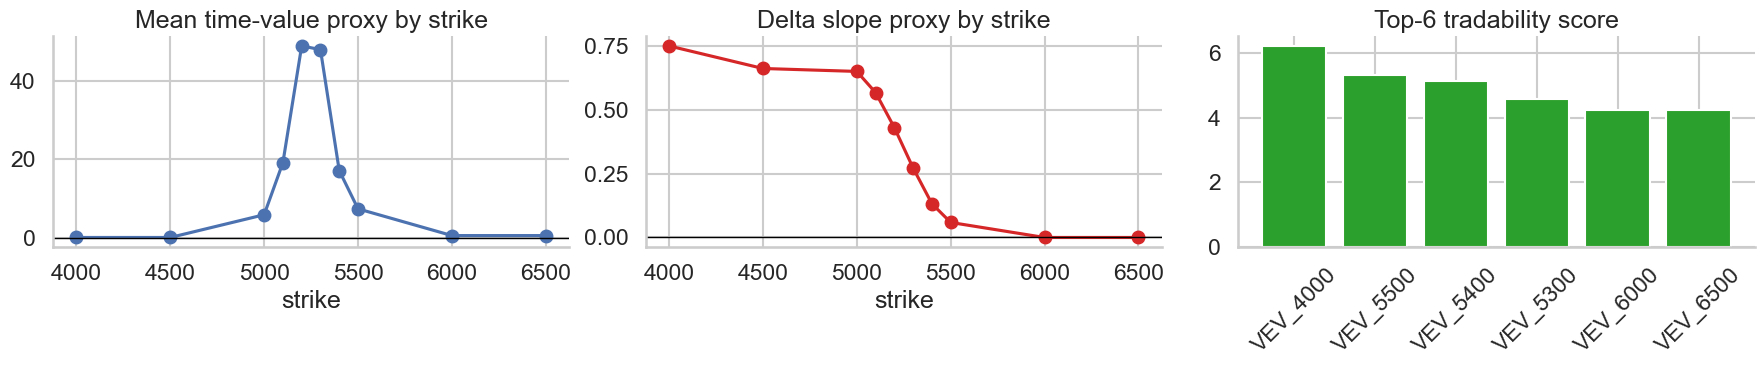

In [8]:
# Deeper structure checks: relation to VELV underlying and strike-dependent sensitivity

# Build underlying (VELV) mid series for timestamp/day alignment
underlying = prices.loc[prices['product'] == 'VELVETFRUIT_EXTRACT', ['day', 'timestamp', 'mid_price']].copy()
underlying = underlying.rename(columns={'mid_price': 'velv_mid'})

vv_struct_rows = []
for product in voucher_products:
    strike = int(product.split('_')[1])
    p = voucher_prices.loc[voucher_prices['product'] == product, ['day', 'timestamp', 'mid_price']].copy()
    p = p.rename(columns={'mid_price': 'vv_mid'})
    m = p.merge(underlying, on=['day', 'timestamp'], how='left').sort_values(['day', 'timestamp'])
    m['intrinsic'] = (m['velv_mid'] - strike).clip(lower=0)
    m['time_value_proxy'] = m['vv_mid'] - m['intrinsic']
    m['d_vv'] = m.groupby('day')['vv_mid'].diff()
    m['d_velv'] = m.groupby('day')['velv_mid'].diff()

    valid = m[['d_vv', 'd_velv']].dropna()
    if len(valid) > 20 and valid['d_velv'].abs().sum() > 0:
        slope = np.polyfit(valid['d_velv'], valid['d_vv'], 1)[0]
        corr = valid['d_vv'].corr(valid['d_velv'])
    else:
        slope = np.nan
        corr = np.nan

    vv_struct_rows.append({
        'symbol': product,
        'strike': strike,
        'mean_intrinsic': m['intrinsic'].mean(),
        'mean_time_value_proxy': m['time_value_proxy'].mean(),
        'pct_negative_time_value': (m['time_value_proxy'] < 0).mean(),
        'delta_slope_proxy': slope,
        'corr_dvv_dvelv': corr,
    })

vv_struct = pd.DataFrame(vv_struct_rows).sort_values('strike').reset_index(drop=True)

# Rank strikes by practical tradability score (activity + movement + not pinned)
rank = summary.merge(vv_struct[['symbol', 'delta_slope_proxy', 'mean_time_value_proxy']], on='symbol', how='left')
rank['is_pinned'] = rank['std_mid'].fillna(0) < 1e-9
rank['tradability_score'] = (
    np.log1p(rank['trade_rows'])
    + 0.15 * rank['mean_abs_mid_change'].fillna(0)
    + 0.5 * rank['imbalance_next_mid_corr'].fillna(0)
    - 1.0 * rank['is_pinned'].astype(float)
)
rank = rank.sort_values('tradability_score', ascending=False)

print('Voucher structure vs underlying:')
display(vv_struct)
print('Top tradability score strikes:')
display(rank[['symbol', 'strike', 'trade_rows', 'std_mid', 'mean_abs_mid_change', 'imbalance_next_mid_corr', 'delta_slope_proxy', 'tradability_score']].head(10))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(vv_struct['strike'], vv_struct['mean_time_value_proxy'], marker='o')
axes[0].axhline(0, color='black', lw=1)
axes[0].set_title('Mean time-value proxy by strike')
axes[0].set_xlabel('strike')

axes[1].plot(vv_struct['strike'], vv_struct['delta_slope_proxy'], marker='o', color='#d62728')
axes[1].axhline(0, color='black', lw=1)
axes[1].set_title('Delta slope proxy by strike')
axes[1].set_xlabel('strike')

axes[2].bar(rank['symbol'].head(6), rank['tradability_score'].head(6), color='#2ca02c')
axes[2].set_title('Top-6 tradability score')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()

## Notes

- The voucher ladder behaves very differently by strike, so any strategy should be strike-specific rather than family-wide.
- The deepest OTM strikes are pinned and probably only useful as boundary checks.
- The lower strikes carry the most structure and the best candidate signal for a first-pass option model.